# 01. Data Cleaning and RFM Analysis
## Who Deserves the Next Retention Dollar?

This notebook prepares the Online Retail II dataset and examines customer purchasing behavior using recency, frequency and monetary value (RFM). The resulting customer profiles support the 90-day repeat-purchase model. All monetary values are in GBP.

## 1. Imports and project settings

The analysis uses Python and pandas, with a fixed historical snapshot and observation window.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project folders
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "online_retail_II.xlsx"
OUTPUT = ROOT / "outputs"

if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

OUTPUT.mkdir(exist_ok=True)

HISTORY_DAYS = 180     # Fixed observation window; compare with longer history as a sensitivity check later
OUTCOME_DAYS = 90      # Future repeat-purchase label, built in Notebook 02
SNAPSHOT = pd.Timestamp('2011-09-10')  # Historical decision date; 90-day future must be observed
DROP_EXACT_DUPLICATES = False  # Do not assume identical invoice lines are data-entry mistakes
print('Dataset:', DATA_FILE)
print('Historical snapshot:', SNAPSHOT.date())

Dataset: c:\Users\user\Documents\Wright\Capstone\Capstone Retention Project\retention-scoring-capstone\data\online_retail_II.xlsx
Historical snapshot: 2011-09-10


## 2. Load and inspect transaction data

The dataset contains two years of invoice lines. Following Field Guide 03, an order is defined as one customer purchasing on one calendar day, regardless of the number of invoices.

In [5]:
excel = pd.ExcelFile(DATA_FILE)
raw = pd.concat([pd.read_excel(excel, sheet_name=s) for s in excel.sheet_names], ignore_index=True)
raw['InvoiceDate'] = pd.to_datetime(raw['InvoiceDate'], errors='coerce')
raw['Invoice'] = raw['Invoice'].astype('string').str.strip()
raw['StockCode'] = raw['StockCode'].astype('string').str.strip()
print('Sheets:', excel.sheet_names)
print('Raw invoice lines:', f'{len(raw):,}')
print('Unique known customers:', f"{raw['Customer ID'].nunique():,}")
print('Date range:', raw['InvoiceDate'].min(), 'to', raw['InvoiceDate'].max())
print('Columns:', raw.columns.tolist())
display(raw.head())
assert SNAPSHOT + pd.Timedelta(days=OUTCOME_DAYS) <= raw['InvoiceDate'].max(), 'Not enough future data for the 90-day label' 

Sheets: ['Year 2009-2010', 'Year 2010-2011']
Raw invoice lines: 1,067,371
Unique known customers: 5,942
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 3. Clean transaction records

The analysis retains identifiable customers with valid dates, positive quantities and prices, and non-cancelled invoices. Duplicate-looking lines are retained because they may represent legitimate purchases. Returns are not matched to original orders, so spending represents gross positive sales rather than net revenue or profit.

In [6]:
audit = []
def record(stage, frame, removed=0):
    audit.append({'Stage': stage, 'Lines remaining': len(frame), 'Lines removed at step': removed,
                  'Customers remaining': frame['Customer ID'].nunique()})

work = raw.copy()
record('Raw data', work)

def exclude(stage, mask):
    global work
    removed = int(mask.sum())
    work = work.loc[~mask].copy()
    record(stage, work, removed)

exclude('Missing customer ID or date', work['Customer ID'].isna() | work['InvoiceDate'].isna())
exclude('Cancellation invoices (C prefix)', work['Invoice'].str.upper().str.startswith('C').fillna(False))
exclude('Nonpositive quantity or price', (work['Quantity'] <= 0) | (work['Price'] <= 0) |
        work['Quantity'].isna() | work['Price'].isna())
if DROP_EXACT_DUPLICATES:
    exclude('Exact duplicate rows', work.duplicated(keep='first'))

work['Customer ID'] = work['Customer ID'].astype('int64')
work['SalesGBP'] = work['Quantity'] * work['Price']
audit_table = pd.DataFrame(audit)
display(audit_table)
audit_table.to_csv(OUTPUT / '01_cleaning_audit.csv', index=False)
print('Clean purchase lines:', f'{len(work):,}', '| Customers:', f"{work['Customer ID'].nunique():,}")
assert work['SalesGBP'].gt(0).all()
assert work['Customer ID'].notna().all()

,Stage,Lines remaining,Lines removed at step,Customers remaining
0,Raw data,1067371,0,5942
1,Missing customer ID or date,824364,243007,5942
2,Cancellation invoices (C prefix),805620,18744,5881
3,Nonpositive quantity or price,805549,71,5878


Clean purchase lines: 805,549 | Customers: 5,878


## 4. Cancellation and stock code audit

Cancellation values and unusual stock codes are examined separately to assess potential limitations in the spending measures.

In [7]:
cancellations = raw.loc[
    raw['Invoice'].str.upper().str.startswith('C').fillna(False) & raw['Customer ID'].notna()
].copy()
cancellations['ReturnValueGBP'] = cancellations['Quantity'] * cancellations['Price']
print('Cancellation lines with customer ID:', f'{len(cancellations):,}')
print('Signed cancellation value (£):', f"{cancellations['ReturnValueGBP'].sum():,.2f}")
print('Gross positive purchase value (£):', f"{work['SalesGBP'].sum():,.2f}")
nonproduct_codes = ['POST', 'C2', 'DOT', 'BANK CHARGES', 'ADJUST', 'ADJUST2', 'TEST001', 'TEST002', 'D']
code_audit = work.loc[work['StockCode'].isin(nonproduct_codes)].groupby('StockCode').agg(
    Lines=('SalesGBP','size'), SalesGBP=('SalesGBP','sum')).sort_values('SalesGBP',ascending=False)
display(code_audit)
code_audit.to_csv(OUTPUT / '01_unusual_code_audit.csv')

Cancellation lines with customer ID: 18,744
Signed cancellation value (£): -1,095,136.79
Gross positive purchase value (£): 17,743,429.18


,Lines,SalesGBP
StockCode,,
POST,1838,126563.040
C2,253,12796.000
DOT,16,11906.360
ADJUST,32,3538.520
ADJUST2,3,731.050
BANK CHARGES,32,465.001
D,5,397.890
TEST001,9,225.000
TEST002,1,1.000


## 5. Customer snapshot and RFM features

The snapshot is September 10, 2011. Recency measures days since the last purchase; frequency counts distinct purchase days and monetary value measures gross spending over the preceding 180 days. Historical spending covers all observed purchases up to the snapshot and is kept separate from recent monetary value. Customer tenure varies.

In [8]:
work['PurchaseDay'] = work['InvoiceDate'].dt.normalize()
history = work.loc[work['InvoiceDate'] <= SNAPSHOT].copy()
window_start = SNAPSHOT - pd.Timedelta(days=HISTORY_DAYS)
recent = history.loc[history['InvoiceDate'] > window_start].copy()

all_customers = history.groupby('Customer ID').agg(
    FirstPurchase=('InvoiceDate', 'min'),
    LastPurchase=('InvoiceDate', 'max'),
    HistoricalOrders=('PurchaseDay', 'nunique'),
    HistoricalSpendGBP=('SalesGBP', 'sum')
)
recent_rfm = recent.groupby('Customer ID').agg(
    Frequency=('PurchaseDay', 'nunique'),
    MonetaryGBP=('SalesGBP', 'sum')
)
rfm = all_customers.join(recent_rfm, how='left')
rfm[['Frequency', 'MonetaryGBP']] = rfm[['Frequency', 'MonetaryGBP']].fillna(0)
rfm['Frequency'] = rfm['Frequency'].astype(int)
rfm['RecencyDays'] = (SNAPSHOT - rfm['LastPurchase']).dt.total_seconds() / 86400
rfm['ObservedTenureDays'] = (SNAPSHOT - rfm['FirstPurchase']).dt.total_seconds() / 86400
rfm['SnapshotDate'] = SNAPSHOT
rfm = rfm.reset_index()
assert rfm['Customer ID'].is_unique
assert rfm['RecencyDays'].ge(0).all()
assert rfm['HistoricalSpendGBP'].ge(rfm['MonetaryGBP']).all()
print('Eligible customers at snapshot:', f'{len(rfm):,}')
print('Customers with zero purchases in last 180 days:', f"{(rfm['Frequency']==0).sum():,}")
display(rfm[['RecencyDays', 'Frequency', 'MonetaryGBP', 'HistoricalSpendGBP', 'ObservedTenureDays']].describe().round(2))

Eligible customers at snapshot: 5,281
Customers with zero purchases in last 180 days: 2,494


,RecencyDays,Frequency,MonetaryGBP,HistoricalSpendGBP,ObservedTenureDays
count,5281.00,5281.00,5281.00,5281.00,5281.00
mean,207.27,1.38,691.40,2705.44,431.77
std,175.02,2.75,3375.03,12535.83,180.51
min,0.34,0.00,0.00,2.90,0.41
25%,49.42,0.00,0.00,323.86,311.35
50%,163.54,1.00,110.23,804.02,473.55
75%,326.35,2.00,552.00,2118.75,586.47
max,647.59,61.00,120436.60,484615.10,647.68


## 6. RFM scoring and customer segmentation

Recency and monetary scores use percentile ranks with ties preserved. Frequency scores use purchase-day groups of 0, 1, 2, 3–4 and 5 or more. The At Risk / High Value segment takes priority over general inactivity and combines more than 90 days of inactivity with spending at or above the historical 75th percentile. These are business rules, not optimized cutoffs.

In [9]:
def percentile_score(values, higher_is_better=True):
    pct = values.rank(method='average', pct=True)
    score = np.ceil(pct * 5).clip(1, 5).astype(int)
    return score if higher_is_better else 6 - score

rfm['R_score'] = percentile_score(rfm['RecencyDays'], higher_is_better=False)
rfm['F_score'] = np.select(
    [rfm['Frequency'].eq(0), rfm['Frequency'].eq(1), rfm['Frequency'].eq(2),
     rfm['Frequency'].between(3, 4), rfm['Frequency'].ge(5)],
    [1, 2, 3, 4, 5]
).astype(int)
rfm['M_score'] = percentile_score(rfm['MonetaryGBP'], higher_is_better=True)

rfm['RFMCode'] = rfm[['R_score', 'F_score', 'M_score']].astype(str).agg(''.join, axis=1)
frequency_groups = rfm.groupby('F_score').size().reindex(range(1, 6), fill_value=0).rename('Customers')
display(frequency_groups.to_frame())

HIGH_VALUE_QUANTILE = 0.75
AT_RISK_DAYS = 90
high_value_cutoff = rfm['HistoricalSpendGBP'].quantile(HIGH_VALUE_QUANTILE)
rfm['HistoricallyHighValue'] = rfm['HistoricalSpendGBP'] >= high_value_cutoff

# Business rules use only information available at the snapshot.
def name_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if row['RecencyDays'] > AT_RISK_DAYS and row['HistoricallyHighValue']:
        return 'At Risk / High Value'
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    if r >= 3 and f >= 3:
        return 'Loyal'
    if r >= 4 and f <= 2:
        return 'Recent / Occasional'
    if row['RecencyDays'] > AT_RISK_DAYS:
        return 'Inactive / Low Frequency'
    return 'Needs Attention'

rfm['Segment'] = rfm.apply(name_segment, axis=1)
summary = rfm.groupby('Segment').agg(
    Customers=('Customer ID', 'size'),
    MedianRecencyDays=('RecencyDays', 'median'),
    MedianOrders180d=('Frequency', 'median'),
    GrossSales180dGBP=('MonetaryGBP', 'sum'),
    HistoricalGrossSalesGBP=('HistoricalSpendGBP', 'sum'),
    MedianSpend180dGBP=('MonetaryGBP', 'median'),
    MedianHistoricalSpendGBP=('HistoricalSpendGBP', 'median')
).sort_values('Customers', ascending=False)
summary['CustomerSharePct'] = 100 * summary['Customers'] / len(rfm)
summary['SalesSharePct'] = 100 * summary['GrossSales180dGBP'] / rfm['MonetaryGBP'].sum()
summary['HistoricalSalesSharePct'] = 100 * summary['HistoricalGrossSalesGBP'] / rfm['HistoricalSpendGBP'].sum()

print(f'Historically high-value cutoff (top 25%): £{high_value_cutoff:,.2f}')
print('At Risk / High Value customers:', int((rfm['Segment'] == 'At Risk / High Value').sum()))
print('Note: Historical spending is cumulative and should not be interpreted as current revenue at risk.')
display(summary.round(2))
assert summary['Customers'].sum() == len(rfm)
assert (rfm.loc[rfm['Segment'].eq('At Risk / High Value'), 'RecencyDays'] > AT_RISK_DAYS).all()
assert rfm.loc[rfm['Segment'].eq('At Risk / High Value'), 'HistoricallyHighValue'].all()

,Customers
F_score,
1,2494
2,1308
3,620
4,504
5,355


Historically high-value cutoff (top 25%): £2,118.75
At Risk / High Value customers: 396
Note: Historical spending is cumulative and should not be interpreted as current revenue at risk.


,Customers,MedianRecencyDays,MedianOrders180d,GrossSales180dGBP,HistoricalGrossSalesGBP,MedianSpend180dGBP,MedianHistoricalSpendGBP,CustomerSharePct,SalesSharePct,HistoricalSalesSharePct
Segment,,,,,,,,,,
Inactive / Low Frequency,2769,313.32,0.0,136812.36,1632245.93,0.00,417.94,52.43,3.75,11.42
Champions,822,19.34,4.0,2572464.06,8324910.54,1506.30,4287.61,15.57,70.45,58.27
Recent / Occasional,701,54.48,1.0,266485.91,929693.10,267.00,677.90,13.27,7.30,6.51
Loyal,593,43.27,2.0,443820.66,1275521.69,589.15,1381.66,11.23,12.16,8.93
At Risk / High Value,396,189.48,0.0,231694.11,2125037.18,0.00,3351.71,7.50,6.35,14.87


## 7. Order value and segment economics

Repeat revenue is gross sales after the first observed customer-day order, which may not be the first lifetime order. Revenue-at-stake scenarios apply assumed fractions of 5%, 10% and 20% to historical gross sales; they are illustrations rather than forecasts or profit estimates.

In [10]:
orders = history.groupby(['Customer ID', 'PurchaseDay'], as_index=False)['SalesGBP'].sum()
order_stats = orders['SalesGBP'].describe(percentiles=[.25, .5, .75])
display(order_stats.round(2))
print(f"Median historical customer-day order value: £{orders['SalesGBP'].median():,.2f}")
first_orders = orders.sort_values('PurchaseDay').drop_duplicates('Customer ID').set_index('Customer ID')['SalesGBP']
rfm['RepeatRevenueGBP'] = rfm['HistoricalSpendGBP'] - rfm['Customer ID'].map(first_orders)
assert rfm['RepeatRevenueGBP'].ge(-1e-8).all()
summary['AverageHistoricalRevenuePerCustomerGBP'] = summary['HistoricalGrossSalesGBP'] / summary['Customers']
summary['AverageRevenue180dPerCustomerGBP'] = summary['GrossSales180dGBP'] / summary['Customers']
summary['RepeatRevenueGBP'] = rfm.groupby('Segment')['RepeatRevenueGBP'].sum()
for fraction in [.05, .10, .20]:
    summary[f'IllustrativeRevenueAtStake_{fraction:.0%}_GBP'] = summary['Customers'] * summary['AverageHistoricalRevenuePerCustomerGBP'] * fraction
display(summary[['Customers', 'AverageHistoricalRevenuePerCustomerGBP', 'AverageRevenue180dPerCustomerGBP', 'RepeatRevenueGBP'] + [c for c in summary if c.startswith('Illustrative')]].round(2))
order_stats.to_csv(OUTPUT / '01_order_value_summary.csv', header=['OrderValueGBP'])
frequency_groups.to_csv(OUTPUT / '01_frequency_groups.csv')

count    27151.00
mean       526.22
std       1257.94
min          0.85
25%        181.58
50%        314.51
75%        521.56
max      77183.60
Name: SalesGBP, dtype: float64

Median historical customer-day order value: £314.51


,Customers,AverageHistoricalRevenuePerCustomerGBP,AverageRevenue180dPerCustomerGBP,RepeatRevenueGBP,IllustrativeRevenueAtStake_5%_GBP,IllustrativeRevenueAtStake_10%_GBP,IllustrativeRevenueAtStake_20%_GBP
Segment,,,,,,,
Inactive / Low Frequency,2769,589.47,49.41,775172.75,81612.30,163224.59,326449.19
Champions,822,10127.63,3129.52,7808211.33,416245.53,832491.05,1664982.11
Recent / Occasional,701,1326.24,380.15,659204.12,46484.66,92969.31,185938.62
Loyal,593,2150.96,748.43,1038049.61,63776.08,127552.17,255104.34
At Risk / High Value,396,5366.26,585.09,1652694.19,106251.86,212503.72,425007.44


## 8. Customer segment visualizations

The charts compare segment sizes and shares of recent gross sales. Historical and recent spending are distinct measures, particularly for inactive customers.

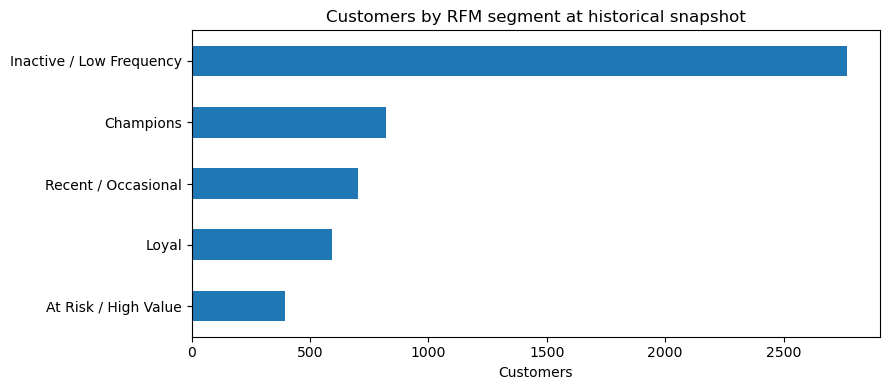

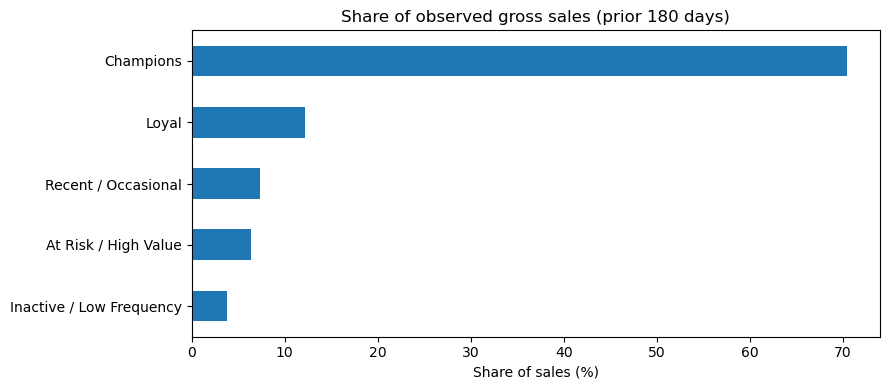

In [11]:
fig, ax = plt.subplots(figsize=(9,4))
summary['Customers'].sort_values().plot.barh(ax=ax)
ax.set_title('Customers by RFM segment at historical snapshot')
ax.set_xlabel('Customers')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9,4))
summary['SalesSharePct'].sort_values().plot.barh(ax=ax)
ax.set_title('Share of observed gross sales (prior 180 days)')
ax.set_xlabel('Share of sales (%)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 9. Export cleaned data and customer profiles

The cleaned transactions and RFM summaries provide the inputs for the repeat-purchase model and subsequent targeting analysis.

In [12]:
work.to_pickle(OUTPUT / '01_clean_purchase_lines.pkl')
rfm.to_csv(OUTPUT / '01_customer_rfm_snapshot.csv', index=False)
summary.to_csv(OUTPUT / '01_rfm_segment_summary.csv')
print('Saved cleaned transactions, RFM snapshot, segment summary and audit files in:', OUTPUT.resolve())
print('Next: Notebook 02 will build historical training/validation/test snapshots and compare logistic regression against simple baselines.')

Saved cleaned transactions, RFM snapshot, segment summary and audit files in: C:\Users\user\Documents\Wright\Capstone\Capstone Retention Project\retention-scoring-capstone\outputs
Next: Notebook 02 will build historical training/validation/test snapshots and compare logistic regression against simple baselines.


## 10. Findings and limitations

The cleaned dataset contains 805,549 purchase lines and 5,878 customers, of whom 5,281 appear at the historical snapshot. The median customer-day order value is £314.51. Rule-based RFM segmentation provides an interpretable view of customer behavior without clustering. Historical spending is affected by observed tenure and excludes matched-return reconciliation. These descriptive measures do not establish future revenue or campaign effectiveness.